# VED exploration notebook

This notebook explores one weekly dynamic CSV from the Vehicle Energy Dataset (VED) plus the two static Excel files. Goal: understand what the Spark cleaning job needs to do.

## Setup
Imports, paths and matplotlib config. The raw data lives under `Data/raw/`.

In [1]:
%matplotlib inline
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path('../Data/raw')
SAMPLE_CSV = RAW_DIR / 'VED_171101_week.csv'
STATIC_ICE = RAW_DIR / 'VED_Static_Data_ICE&HEV.xlsx'
STATIC_PHEV = RAW_DIR / 'VED_Static_Data_PHEV&EV.xlsx'
print(RAW_DIR.resolve())

D:\Faks\VedSparkBatchAnalysis\Data\raw


## 1. Files: count and total size
List the weekly CSV files (no reading of content) and the two Excel files, with sizes.

In [2]:
weekly_files = sorted(RAW_DIR.glob('VED_*_week.csv'))
n_files = len(weekly_files)
total_bytes = sum(f.stat().st_size for f in weekly_files)
print(f'weekly CSV files: {n_files}')
print(f'total size: {total_bytes / 1024**3:.2f} GB')

weekly CSV files: 54
total size: 2.98 GB


Also show the per-file size as a small table so we can see how uneven the weeks are.

In [3]:
file_sizes = pd.DataFrame({
    'file': [f.name for f in weekly_files],
    'size_mb': [f.stat().st_size / 1024**2 for f in weekly_files],
})
file_sizes.describe()

,size_mb
count,54.000000
mean,56.576830
std,12.468096
min,15.962038
25%,49.335030
50%,55.317085
75%,62.653635
max,92.199030


In [4]:
static_files = [STATIC_ICE, STATIC_PHEV]
for f in static_files:
    print(f'{f.name}: {f.stat().st_size / 1024:.1f} KB')

VED_Static_Data_ICE&HEV.xlsx: 20.7 KB
VED_Static_Data_PHEV&EV.xlsx: 9.5 KB


## 2. Structure of a weekly CSV
Load one weekly CSV in full and look at columns, types and a few sample rows.

In [5]:
df = pd.read_csv(SAMPLE_CSV)
print(f'loaded {SAMPLE_CSV.name}: {len(df):,} rows, {df.shape[1]} columns')

loaded VED_171101_week.csv: 489,414 rows, 22 columns


In [6]:
df.dtypes

DayNum                            float64
VehId                               int64
Trip                                int64
Timestamp(ms)                       int64
Latitude[deg]                     float64
Longitude[deg]                    float64
Vehicle Speed[km/h]               float64
MAF[g/sec]                        float64
Engine RPM[RPM]                   float64
Absolute Load[%]                  float64
OAT[DegC]                         float64
Fuel Rate[L/hr]                   float64
Air Conditioning Power[kW]        float64
Air Conditioning Power[Watts]     float64
Heater Power[Watts]               float64
HV Battery Current[A]             float64
HV Battery SOC[%]                 float64
HV Battery Voltage[V]             float64
Short Term Fuel Trim Bank 1[%]    float64
Short Term Fuel Trim Bank 2[%]    float64
Long Term Fuel Trim Bank 1[%]     float64
Long Term Fuel Trim Bank 2[%]     float64
dtype: object

In [7]:
df.head(5)

,DayNum,VehId,Trip,Timestamp(ms),Latitude[deg],Longitude[deg],Vehicle Speed[km/h],MAF[g/sec],Engine RPM[RPM],Absolute Load[%],...,Air Conditioning Power[kW],Air Conditioning Power[Watts],Heater Power[Watts],HV Battery Current[A],HV Battery SOC[%],HV Battery Voltage[V],Short Term Fuel Trim Bank 1[%],Short Term Fuel Trim Bank 2[%],Long Term Fuel Trim Bank 1[%],Long Term Fuel Trim Bank 2[%]
0,1.586651,8,706,0,42.277558,-83.69875,40.0,22.129999,2285.0,49.019608,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.586651,8,706,200,42.277558,-83.69875,40.0,22.129999,2285.0,67.450981,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.586651,8,706,1100,42.277558,-83.69875,45.0,22.129999,2285.0,67.450981,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.586651,8,706,2100,42.277558,-83.69875,47.0,6.150000,2744.0,67.450981,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.586651,8,706,4200,42.277558,-83.69875,48.0,21.440001,1982.0,67.450981,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Missing values
Share of missing values per column, both as a table and as a bar chart.

In [8]:
missing_pct = df.isna().mean().mul(100).round(2).sort_values(ascending=False)
missing_pct.to_frame('missing_%')

,missing_%
Heater Power[Watts],99.26
Air Conditioning Power[kW],96.72
Fuel Rate[L/hr],96.72
Short Term Fuel Trim Bank 2[%],95.31
Long Term Fuel Trim Bank 2[%],95.31
Air Conditioning Power[Watts],92.01
HV Battery Voltage[V],88.73
HV Battery SOC[%],88.73
HV Battery Current[A],88.73
OAT[DegC],88.73


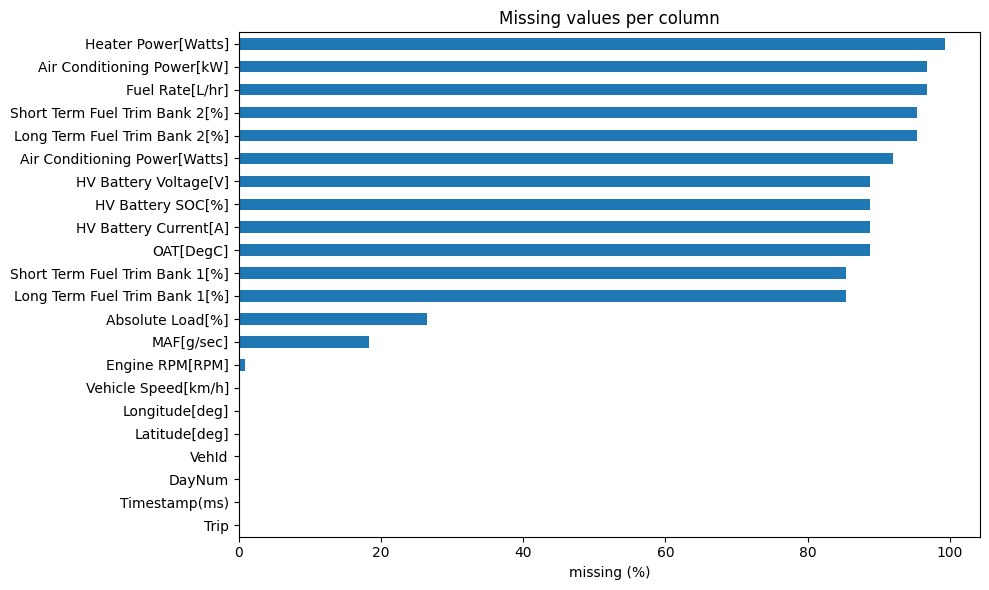

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
missing_pct.plot(kind='barh', ax=ax)
ax.set_xlabel('missing (%)')
ax.set_title('Missing values per column')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Value ranges and obviously invalid values
Summary statistics of numeric columns, then quick sanity checks.

In [10]:
df.describe().T[['min', 'mean', 'max']]

,min,mean,max
DayNum,1.002938,4.550381,7.999698e+00
VehId,8.000000,368.314004,6.080000e+02
Trip,2.000000,772.226481,2.519000e+03
Timestamp(ms),0.000000,486585.702289,8.646500e+06
Latitude[deg],42.220316,42.271751,4.232557e+01
Longitude[deg],-83.804136,-83.731072,-8.367402e+01
Vehicle Speed[km/h],0.000000,37.981551,1.350000e+02
MAF[g/sec],0.000000,10.301399,1.655500e+02
Engine RPM[RPM],0.000000,1180.788386,5.502000e+03
Absolute Load[%],0.000000,28.657684,5.439216e+02


Count rows that violate basic physical constraints.

In [11]:
checks = {
    'speed < 0': (df['Vehicle Speed[km/h]'] < 0).sum(),
    'speed > 250': (df['Vehicle Speed[km/h]'] > 250).sum(),
    'SOC < 0': (df['HV Battery SOC[%]'] < 0).sum(),
    'SOC > 100': (df['HV Battery SOC[%]'] > 100).sum(),
    'latitude == 0': (df['Latitude[deg]'] == 0).sum(),
    'longitude == 0': (df['Longitude[deg]'] == 0).sum(),
    'OAT < -50': (df['OAT[DegC]'] < -50).sum(),
    'OAT > 55': (df['OAT[DegC]'] > 55).sum(),
    'engine RPM < 0': (df['Engine RPM[RPM]'] < 0).sum(),
}
pd.Series(checks, name='rows')

speed < 0         0
speed > 250       0
SOC < 0           0
SOC > 100         0
latitude == 0     0
longitude == 0    0
OAT < -50         0
OAT > 55          0
engine RPM < 0    0
Name: rows, dtype: int64

## 5. Text columns that should be numeric
Look for `object` dtypes among the numeric-looking columns and inspect why.

In [12]:
object_cols = df.select_dtypes(include='object').columns.tolist()
object_cols

[]

For each object-typed numeric column, show the few distinct non-numeric values that forced pandas to parse it as text.

In [13]:
for col in object_cols:
    coerced = pd.to_numeric(df[col], errors='coerce')
    bad = df.loc[coerced.isna() & df[col].notna(), col].unique()[:10]
    print(f'{col}: sample non-numeric values = {bad}')

## 6. Vehicles and trips
Distinct vehicles, distinct trips, and how many readings per trip (so we know granularity).

In [14]:
n_vehicles = df['VehId'].nunique()
n_trips = df.groupby(['VehId', 'Trip']).ngroups
print(f'distinct vehicles: {n_vehicles}')
print(f'distinct (VehId, Trip) pairs: {n_trips}')

distinct vehicles: 258
distinct (VehId, Trip) pairs: 854


In [15]:
readings_per_trip = df.groupby(['VehId', 'Trip']).size()
readings_per_trip.describe().round(1)

count     854.0
mean      573.1
std       483.2
min       101.0
25%       231.2
50%       449.0
75%       753.8
max      6358.0
dtype: float64

## 7. Time: Timestamp(ms), DayNum, dates
Check whether `Timestamp(ms)` restarts per trip, measure the typical gap between consecutive readings, convert `DayNum` to a real datetime, and compare the resulting date range with the file name.

In [16]:
trip_ts_start = df.groupby(['VehId', 'Trip'])['Timestamp(ms)'].min()
trip_ts_start.describe()

count    854.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: Timestamp(ms), dtype: float64

If the first `Timestamp(ms)` of every trip is 0, the counter is trip-relative.

In [17]:
share_starting_at_zero = (trip_ts_start == 0).mean()
print(f'trips whose Timestamp(ms) starts at 0: {share_starting_at_zero:.1%}')

trips whose Timestamp(ms) starts at 0: 100.0%


Gap between consecutive readings within each trip.

In [18]:
df_sorted = df.sort_values(['VehId', 'Trip', 'Timestamp(ms)'])
gaps = df_sorted.groupby(['VehId', 'Trip'])['Timestamp(ms)'].diff()
gaps.describe()

count    4.885600e+05
mean     9.577657e+02
std      4.777539e+03
min      1.000000e+02
25%      4.000000e+02
50%      9.000000e+02
75%      1.100000e+03
max      2.341700e+06
Name: Timestamp(ms), dtype: float64

Convert `DayNum` to a real datetime. `DayNum` = days since 2017-11-01 with `DayNum == 1` meaning 2017-11-01 00:00, so the offset is `DayNum - 1` days from that anchor.

In [19]:
anchor = pd.Timestamp('2017-11-01')
df['event_time'] = anchor + pd.to_timedelta(df['DayNum'] - 1, unit='D')
df['event_time'].agg(['min', 'max'])

min   2017-11-01 00:04:13.838400480
max   2017-11-07 23:59:33.893599776
Name: event_time, dtype: datetime64[ns]

File name `VED_171101_week.csv` encodes the week starting 2017-11-01. Expected window: 2017-11-01 to 2017-11-07.

In [20]:
expected_week_start = pd.Timestamp('2017-11-01')
expected_week_end = expected_week_start + pd.Timedelta(days=7)
actual_min = df['event_time'].min()
actual_max = df['event_time'].max()
print(f'expected: [{expected_week_start}, {expected_week_end})')
print(f'actual:   [{actual_min}, {actual_max}]')

expected: [2017-11-01 00:00:00, 2017-11-08 00:00:00)
actual:   [2017-11-01 00:04:13.838400480, 2017-11-07 23:59:33.893599776]


## 8. Duplicates
Are there exact duplicate rows?

In [21]:
n_dup_full = df.duplicated().sum()
n_dup_key = df.duplicated(subset=['VehId', 'Trip', 'Timestamp(ms)']).sum()
print(f'full-row duplicates: {n_dup_full}')
print(f'duplicate (VehId, Trip, Timestamp(ms)): {n_dup_key}')

full-row duplicates: 0
duplicate (VehId, Trip, Timestamp(ms)): 0


## 9. Static data: two Excel files
Load both, compare columns, inspect categorical values and "NO DATA" markers, count vehicles, and check for ID overlap.

In [22]:
static_ice = pd.read_excel(STATIC_ICE)
static_phev = pd.read_excel(STATIC_PHEV)
print('ICE/HEV columns: ', list(static_ice.columns))
print('PHEV/EV columns: ', list(static_phev.columns))

ICE/HEV columns:  ['VehId', 'Vehicle Type', 'Vehicle Class', 'Engine Configuration & Displacement', 'Transmission', 'Drive Wheels', 'Generalized_Weight']
PHEV/EV columns:  ['VehId', 'EngineType', 'Vehicle Class', 'Engine Configuration & Displacement', 'Transmission', 'Drive Wheels', 'Generalized_Weight']


In [23]:
same_cols = list(static_ice.columns) == list(static_phev.columns)
only_in_ice = set(static_ice.columns) - set(static_phev.columns)
only_in_phev = set(static_phev.columns) - set(static_ice.columns)
print(f'identical column order & names: {same_cols}')
print(f'only in ICE/HEV: {only_in_ice}')
print(f'only in PHEV/EV: {only_in_phev}')

identical column order & names: False
only in ICE/HEV: {'Vehicle Type'}
only in PHEV/EV: {'EngineType'}


Normalise the engine-type column name so both files use the same name, then combine them for joint analysis.

In [24]:
static_ice_r = static_ice.rename(columns={'Vehicle Type': 'EngineType'})
static_phev_r = static_phev.copy()
static_all = pd.concat([static_ice_r, static_phev_r], ignore_index=True)
static_all.head()

,VehId,EngineType,Vehicle Class,Engine Configuration & Displacement,Transmission,Drive Wheels,Generalized_Weight
0,2,ICE,Car,4-FI 2.0L T/C,NO DATA,NO DATA,3500
1,5,HEV,Car,4-GAS/ELECTRIC 2.0L,NO DATA,NO DATA,3500
2,7,ICE,SUV,6-FI 3.6L,AUTOMATIC,NO DATA,4500
3,8,ICE,Car,4-FI 1.5L,5-SP MANUAL,NO DATA,2500
4,12,ICE,Car,4-FI 1.8L,NO DATA,NO DATA,2500


Distinct values of each descriptive column.

In [25]:
descriptive_cols = [c for c in static_all.columns if c != 'VehId']
for col in descriptive_cols:
    vals = static_all[col].unique()
    print(f'{col} ({len(vals)} distinct): {vals}')

EngineType (4 distinct): <StringArray>
['ICE', 'HEV', 'PHEV', 'EV']
Length: 4, dtype: str
Vehicle Class (3 distinct): <StringArray>
['Car', 'SUV', 'NO DATA']
Length: 3, dtype: str
Engine Configuration & Displacement (74 distinct): <StringArray>
[               '4-FI 2.0L T/C',          '4-GAS/ELECTRIC 2.0L',
                    '6-FI 3.6L',                    '4-FI 1.5L',
                    '4-FI 1.8L',                 '8-4V/FI 6.0L',
          '4-GAS/ELECTRIC 2.5L',                   '10-FI 6.8L',
               '8-DSL 6.7L T/C',          '4-GAS/ELECTRIC 1.8L',
          '4-GAS/ELECTRIC 2.4L',                    '8-FI 4.7L',
                    '6-FI 3.4L',                    '4-FI 2.4L',
                   '8-FI 5.3L ',                    '6-FI 3.5L',
                    '4-FI 2.5L',                    '4-FI 2.0L',
               '4-FI 2.0L PZEV',                    '8-FI 4.8L',
                    '4-FI 2.2L',          '4-FI 1.3L GAS/ELEC.',
                    '5-FI 2.5L',        

Check how "missing" is encoded in the static data. The strings `NO DATA`, `NO  DATA`, and similar sentinels should be treated as NaN.

In [26]:
sentinel_counts = {}
for col in descriptive_cols:
    s = static_all[col].astype(str).str.strip().str.upper()
    sentinel_counts[col] = int(s.str.contains('NO DATA|NODATA|N/A', regex=True).sum())
pd.Series(sentinel_counts, name='rows_with_NO_DATA_like')

EngineType                               0
Vehicle Class                          352
Engine Configuration & Displacement      0
Transmission                           286
Drive Wheels                           357
Generalized_Weight                      16
Name: rows_with_NO_DATA_like, dtype: int64

In [27]:
n_ice = len(static_ice)
n_phev = len(static_phev)
ids_ice = set(static_ice['VehId'])
ids_phev = set(static_phev['VehId'])
overlap = ids_ice & ids_phev
print(f'rows in ICE/HEV file: {n_ice}')
print(f'rows in PHEV/EV file: {n_phev}')
print(f'total distinct VehIds: {len(ids_ice | ids_phev)}')
print(f'IDs in both files: {len(overlap)} -> {sorted(overlap)[:10]}')

rows in ICE/HEV file: 357
rows in PHEV/EV file: 27
total distinct VehIds: 384
IDs in both files: 0 -> []


## 10. Join check: dynamic vs static
Does every VehId in the dynamic file exist in the static data? After joining, what share of values is missing per column, broken down by engine type?

In [28]:
dyn_ids = set(df['VehId'].unique())
static_ids = set(static_all['VehId'].unique())
missing_from_static = dyn_ids - static_ids
print(f'dynamic vehicles: {len(dyn_ids)}')
print(f'static vehicles: {len(static_ids)}')
print(f'dynamic IDs with no static match: {len(missing_from_static)} -> {sorted(missing_from_static)[:10]}')

dynamic vehicles: 258
static vehicles: 384
dynamic IDs with no static match: 0 -> []


In [29]:
joined = df.merge(static_all[['VehId', 'EngineType']], on='VehId', how='left')
joined['EngineType'].value_counts(dropna=False)

EngineType
ICE     323615
HEV     110630
PHEV     51536
EV        3633
Name: count, dtype: int64

Share of missing per column, split by engine type. This is where we expect ICE rows to have no battery data, EV rows to have no fuel / MAF data, and so on.

In [30]:
missing_by_engine = joined.groupby('EngineType').apply(lambda g: g.isna().mean().mul(100).round(1))
missing_by_engine.T

EngineType,EV,HEV,ICE,PHEV
DayNum,0.0,0.0,0.0,0.0
VehId,0.0,0.0,0.0,0.0
Trip,0.0,0.0,0.0,0.0
Timestamp(ms),0.0,0.0,0.0,0.0
Latitude[deg],0.0,0.0,0.0,0.0
Longitude[deg],0.0,0.0,0.0,0.0
Vehicle Speed[km/h],0.0,0.3,0.1,0.0
MAF[g/sec],100.0,1.3,21.2,31.2
Engine RPM[RPM],100.0,0.3,0.1,0.0
Absolute Load[%],100.0,1.0,22.7,100.0


## 11. Simple plots
Distribution of vehicle speed, outside temperature, and readings per hour of day.

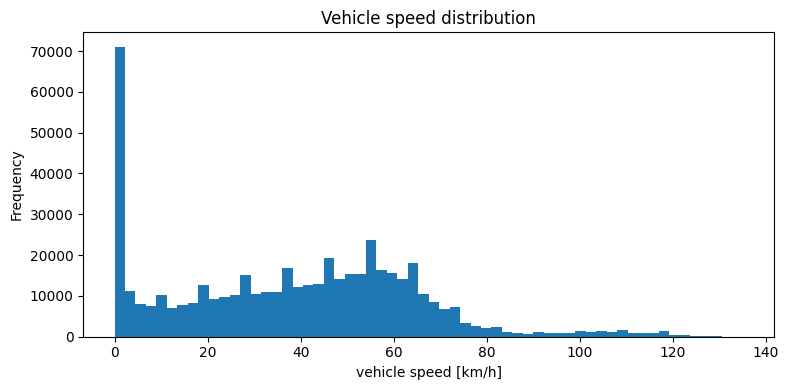

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
df['Vehicle Speed[km/h]'].plot(kind='hist', bins=60, ax=ax)
ax.set_xlabel('vehicle speed [km/h]')
ax.set_title('Vehicle speed distribution')
plt.tight_layout()
plt.show()

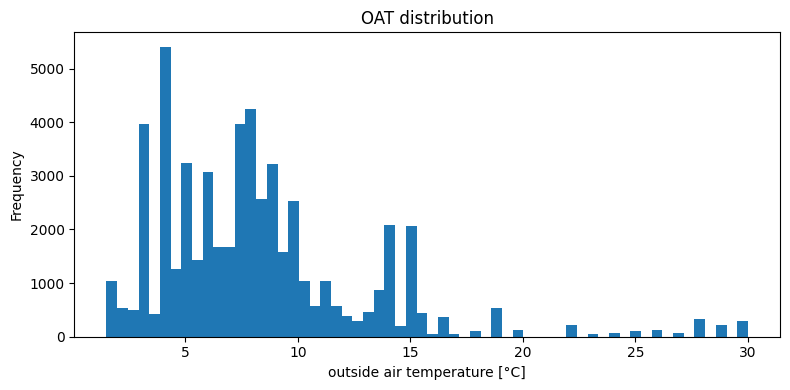

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
df['OAT[DegC]'].dropna().plot(kind='hist', bins=60, ax=ax)
ax.set_xlabel('outside air temperature [°C]')
ax.set_title('OAT distribution')
plt.tight_layout()
plt.show()

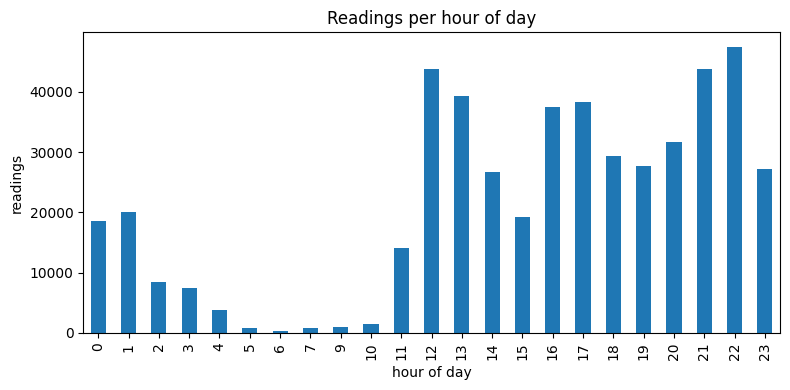

In [33]:
hour_of_day = df['event_time'].dt.hour
fig, ax = plt.subplots(figsize=(8, 4))
hour_of_day.value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_xlabel('hour of day')
ax.set_ylabel('readings')
ax.set_title('Readings per hour of day')
plt.tight_layout()
plt.show()

## Findings and cleaning rules

This section is written for the next step: Spark reading the raw data from HDFS and writing a cleaned Parquet dataset back. Only the facts that affect that job are kept.

### TL;DR

- 54 weekly CSVs, **2.98 GB** total - small enough to clean in a single Spark job.
- Two tiny static Excel files (30 KB combined) must be merged first; they are **not column-compatible**. Merge them **locally into one CSV** before the Spark job runs.
- CSV columns look numeric but the **names are Parquet-illegal** (contain `[`, `]`, `(`, `)`, spaces, `/`). Rename on load.
- Null patterns are **structural** (per engine type), not corruption - never impute.
- `Absolute Load[%]` sometimes exceeds 100% - this is legitimate on turbo engines, **do not drop the row**. Only null out clearly implausible values.
- Verify how the CSVs encode missing values (literal `NaN` vs empty) before running Spark - one wrong row poisons a whole AVG.

### 1. Raw data inventory

| Kind    | Files | Total size | Notes                                                                 |
|---------|------:|-----------:|-----------------------------------------------------------------------|
| Dynamic | 54    | 2.98 GB    | `VED_YYMMDD_week.csv`, 16-92 MB, mean ~ 57 MB. One week per file.    |
| Static  | 2     | 30 KB      | `..._ICE&HEV.xlsx` (357 rows) + `..._PHEV&EV.xlsx` (27 rows).         |

Sample weekly file: **489 414 rows x 22 columns**, 258 vehicles, 854 trips.
Sampling cadence ~ **1 Hz** (median gap 900 ms), but a single trip may contain gaps up to ~39 min - do not assume uniform cadence.

Time span across all 54 weekly files: ~13 months (Nov 2017 - Nov 2018).

### 2. Dynamic schema and renames

All metric columns in the sample parsed as `float64`/`int64`. Raw names contain characters forbidden in Parquet, so rename on load. All values below are what the Spark job should emit.

| Raw column (CSV)                 | Rename to          | Spark type  | Notes                              |
|----------------------------------|--------------------|-------------|------------------------------------|
| DayNum                           | day_num            | DoubleType  | Days since 2017-11-01, 1-based.    |
| VehId                            | veh_id             | IntegerType | FK to static.                      |
| Trip                             | trip               | IntegerType | Unique only within a vehicle.      |
| Timestamp(ms)                    | ts_ms              | LongType    | **Trip-relative** (resets to 0).   |
| Latitude[deg]                    | lat                | DoubleType  |                                    |
| Longitude[deg]                   | lon                | DoubleType  |                                    |
| Vehicle Speed[km/h]              | speed_kmh          | DoubleType  |                                    |
| MAF[g/sec]                       | maf_g_s            | DoubleType  |                                    |
| Engine RPM[RPM]                  | engine_rpm         | DoubleType  |                                    |
| Absolute Load[%]                 | abs_load_pct       | DoubleType  | Values > 100% are legitimate on turbos; see section 4. |
| OAT[DegC]                        | oat_c              | DoubleType  | Only populated for PHEV/EV.        |
| Fuel Rate[L/hr]                  | fuel_rate_l_h      | DoubleType  |                                    |
| Air Conditioning Power[kW]       | ac_power_kw_raw    | DoubleType  | Collapse with next, then drop.     |
| Air Conditioning Power[Watts]    | ac_power_w_raw     | DoubleType  | Collapse with previous, then drop. |
| Heater Power[Watts]              | heater_power_w     | DoubleType  |                                    |
| HV Battery Current[A]            | hv_batt_i_a        | DoubleType  |                                    |
| HV Battery SOC[%]                | hv_batt_soc_pct    | DoubleType  |                                    |
| HV Battery Voltage[V]            | hv_batt_v          | DoubleType  |                                    |
| Short Term Fuel Trim Bank 1[%]   | fuel_trim_st_b1    | DoubleType  |                                    |
| Short Term Fuel Trim Bank 2[%]   | fuel_trim_st_b2    | DoubleType  |                                    |
| Long Term Fuel Trim Bank 1[%]    | fuel_trim_lt_b1    | DoubleType  |                                    |
| Long Term Fuel Trim Bank 2[%]    | fuel_trim_lt_b2    | DoubleType  |                                    |

Load CSVs with an **explicit schema** (`inferSchema=False`).

**Check first how missing values are written in the CSVs.** Open one in a text editor. If empty cells are written as the literal text `NaN`, Spark's CSV reader will parse it as the float NaN (not SQL NULL), and a single NaN will turn any `AVG` into NaN. In that case set `.option("nanValue", "NaN")` and `.option("nullValue", "NaN")` on `spark.read.csv`. If the fields are truly empty (just two commas side by side), nothing extra is needed.

### 3. Derived columns

| Derived           | Formula                                                                             |
|-------------------|-------------------------------------------------------------------------------------|
| `event_time`      | `timestamp('2017-11-01') + make_interval(0,0,0,0,0,0, (day_num - 1) * 86400)`       |
| `event_date`      | `to_date(event_time)` - **kept as a regular column** (not used as partition).       |
| `event_month`     | `date_trunc('month', event_time)` or `date_format(event_time, 'yyyy-MM')` - **this is the Parquet partition column**. |
| `hour_of_day`     | `hour(event_time)`.                                                                 |
| `ac_power_w`      | `coalesce(ac_power_w_raw, ac_power_kw_raw * 1000)` -> drop the two raw columns.     |

`event_time` for `VED_171101_week.csv` lands in `[2017-11-01 00:04, 2017-11-07 23:59]`, matching the filename. Do **not** combine `ts_ms` into `event_time` - it is trip-relative, not absolute.

### 4. Row-level filters and value scrubbing

Two separate kinds of cleaning: **row drops** (key/structural problems) and **value scrubbing** (set a single cell to null, keep the row so its GPS and speed survive).

Row drops - apply these in order:

| Filter (drop row)                                        | Hits in sample | Why                       |
|----------------------------------------------------------|---------------:|---------------------------|
| NULL in `veh_id, trip, ts_ms, day_num`                   | 0              | Keys required             |
| Duplicate `(veh_id, trip, ts_ms)`                        | 0              | Should never happen       |
| `speed_kmh < 0` or `> 250`                               | 0              | Guard                     |
| `lat == 0 AND lon == 0`                                  | 0              | GPS-reset artifact        |

Value scrubbing - set the single cell to NULL but **keep the row**:

| Rule                                                      | Why                        |
|-----------------------------------------------------------|----------------------------|
| `abs_load_pct` > 200 (or < 0) -> null                     | Turbocharged engines legitimately exceed 100% (sample max 543.9% is suspect but 100-200% is plausible). Dropping the row would throw away good GPS and speed. |
| `hv_batt_soc_pct` outside `[0, 100]` -> null              | Physical range             |
| `oat_c < -50` or `> 60` -> null                           | Physical range             |
| `engine_rpm < 0` or `> 10000` -> null                     | Physical range             |

Log the hit count per rule for every week.

### 5. Static table - merge locally, not in Spark

The cluster's Python does **not** have pandas or an Excel reader. Don't try to read the XLSX files inside the Spark job.

Instead, run a small **one-off script on the local machine** (uses this notebook's `ved` env) that does:

1. Read both Excel files with pandas.
2. In the ICE/HEV file, rename `Vehicle Type` -> `EngineType`.
3. `pd.concat` the two.
4. Snake_case columns to: `veh_id, engine_type, vehicle_class, engine_config, transmission, drive_wheels, weight_lb`.
5. Replace literal `"NO DATA"` with empty string in all string columns and in `weight_lb`.
6. Strip whitespace in `engine_config`.
7. Assert `veh_id` is unique (no overlap between the two files - verified in the notebook).
8. Write to `Data/static_merged.csv`.

Upload that one CSV to HDFS alongside the raw dynamic CSVs. The Spark job then reads it with a plain `spark.read.csv(...)` and casts `weight_lb` to `IntegerType`. Empty strings in nullable string columns become NULL automatically with `.option("nullValue", "")`.

Expected: **384 vehicles**. All 258 `veh_id`s seen in the sample dynamic file are present - 0 orphans.

Static column usefulness after cleaning:

| Static column    | "NO DATA" share | Verdict                                                  |
|------------------|----------------:|----------------------------------------------------------|
| engine_type      | 0 %             | **Primary grouping key.**                                |
| weight_lb        | 4 %             | Usable - one of our main group-by columns.               |
| engine_config    | 0 %             | 74 distinct free-text values, needs normalisation.       |
| transmission     | 74 %            | Partial, needs string normalisation to be useful.        |
| vehicle_class    | 92 %            | Mostly unusable.                                         |
| drive_wheels     | 93 %            | Unusable.                                                |

### 6. Join

- Left-join dynamic -> static on `veh_id`.
- Static is 384 rows -> `broadcast(static)` always.
- LEFT (not INNER) so unknown future `veh_id`s surface as NULL `engine_type` rather than silently disappearing.

### 7. Structural nulls - do NOT impute

The per-engine null matrix from section 10 of the notebook shows which columns are populated by which vehicle type.

| Column family                               | ICE | HEV | PHEV   | EV     |
|---------------------------------------------|:---:|:---:|:------:|:------:|
| lat, lon, speed_kmh                         | Y   | Y   | Y      | Y      |
| engine_rpm, maf_g_s, abs_load_pct           | Y   | Y   | partial| -      |
| fuel_trim_* (bank 1 / bank 2)               | Y   | Y   | -      | -      |
| fuel_rate_l_h                               | -   | -   | partial| -      |
| oat_c                                       | -   | -   | Y      | Y      |
| hv_batt_i_a, hv_batt_soc_pct, hv_batt_v     | -   | -   | Y      | Y      |
| heater_power_w                              | -   | -   | -      | Y      |
| ac_power_w (after coalesce)                 | -   | -   | Y      | Y      |

Downstream analytics must `WHERE engine_type IN (...)` before averaging these columns - otherwise aggregates will be silently skewed by structural nulls.

### 8. Analysis-plan implications

The structural-null pattern directly changes what we can analyse:

- **Main groupings that work for all vehicles**: `engine_type`, `hour_of_day`, `event_month`, `weight_lb`. These are our default pivots.
- **`oat_c` is only logged for PHEV and EV** in the sample week. Any "statistics by outside-temperature range" analysis is **restricted to PHEV + EV vehicles**. State this explicitly in the report instead of silently filtering.
- **Battery stats** (`hv_batt_*`, SOC, voltage) -> PHEV + EV only.
- **Fuel-burn stats** (`fuel_rate_l_h`, fuel trims, `maf_g_s`) -> ICE + HEV mainly, partial PHEV.
- **Speed and GPS** are universal and are the only safe inputs for cross-fleet comparisons.

### 9. HDFS and Parquet layout

```
/ved/raw/dynamic/VED_*_week.csv              (as-is, ingestion only)
/ved/raw/static/static_merged.csv            (produced locally, one file)
/ved/cleaned/dynamic/                        Parquet + Snappy, partitioned by event_month
/ved/cleaned/static/                         Parquet, one small file
```

**Partition by `event_month`, not `event_date`.** 2.98 GB of CSV spread over ~380 days is only ~8 MB per day. After Spark cleaning + Snappy compression that drops further, and we would end up with hundreds of tiny Parquet files - HDFS NameNode and Spark both hate that. Monthly partitions give **~13 folders** of ~50-100 MB each, which is the sweet spot for HDFS 128 MB blocks and gives decent pruning on month-range queries. `event_date` stays in the row so day-level filters still work, they just scan one month's partition.

- Keep the Spark job idempotent per month: `write.mode("overwrite").partitionBy("event_month")` lets you reprocess a single month without touching the rest.
- Consider a secondary bucketing on `veh_id` only if per-vehicle aggregations become the dominant query pattern.

### 10. Docker volume location (operational)

HDFS lives inside a Docker volume. **Docker Desktop stores volumes on `C:` by default.** Raw CSVs + cleaned Parquet will total roughly **8-10 GB**. If `C:` is tight (or if everything else in this project is on `D:` for a reason), move Docker's disk image to `D:` **before uploading data**:

> Docker Desktop -> Settings -> Resources -> Advanced -> "Disk image location" -> point to a path on `D:`.

Moving the image after data is in it is possible but involves a stop + copy + reconfigure.

### 11. Watch for across weeks

This notebook only inspected `VED_171101_week.csv`. The Spark job should still assume:

- Other weeks may contain non-numeric strings (e.g. `"NO DATA"` or literal `NaN`) in otherwise-numeric columns. The explicit schema + `mode="PERMISSIVE"` + `_corrupt_record` column will surface them instead of failing silently.
- Invalid-range counts may differ week-to-week. Emit per-rule hit counts as job metrics.
- New vehicles can appear and break the "0 orphan" property. LEFT join plus a post-join assert on NULL `engine_type` is enough.
